# Question-controlled semantic distances and trajectories

Two main panels only: A, role-separated persona-pair heatmaps; B, two question-controlled case studies. The user selected trial 1 only for all five settings: off/155/001/004/046. This is a raw-distance comparison. Existing figures remain separate.

In [1]:
from pathlib import Path
import sys,json,csv
from IPython.display import display,Markdown,Image,Code
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Experiment/shared/task_selection.csv').exists())
sys.path.insert(0,str(ROOT/'Experiment/01_behavioral_diversity/code/semantic'))
import analyze,plot,report
c=analyze.config()
display(Markdown('```json\n'+json.dumps(c,indent=2)+'\n```'))

```json
{
  "arms": [
    "persona_off",
    "candidate_155",
    "candidate_001",
    "candidate_004",
    "candidate_046"
  ],
  "labels": {
    "persona_off": "Persona off",
    "candidate_155": "Persona 155",
    "candidate_001": "Persona 001",
    "candidate_004": "Persona 004",
    "candidate_046": "Persona 046"
  },
  "rollouts": {
    "persona_off": [
      1
    ],
    "candidate_155": [
      1
    ],
    "candidate_001": [
      1
    ],
    "candidate_004": [
      1
    ],
    "candidate_046": [
      1
    ]
  },
  "roles": [
    "simulator",
    "actor"
  ],
  "mode": "raw",
  "model_id": "Qwen/Qwen3-Embedding-0.6B",
  "model_revision": "97b0c614be4d77ee51c0cef4e5f07c00f9eb65b3",
  "embedding_instruction": null,
  "max_model_tokens": 32768,
  "preprocessing": "Strip outer whitespace only; retain generated content; omit metadata, system prompts, injected profiles and transcript history. No summaries, translation or message concatenation.",
  "round_rule": "Round t starts with generated simulator message t, including generated initial inspection requests in review workflows. The next visible actor handoff/question/final specification before the next simulator message is its response. The fixed SciConv input question and pre-first-simulator-reply actor question are excluded. Terminal simulator messages without actor replies remain simulator observations only.",
  "availability_rule": "Trial 1 only for all five settings; original coordinator-finished traces. Include a round only when a nonempty role message exists under all five settings. Use this common T_q for all ten persona pairs within each question and role. No truncation to 3\u20134 rounds, padding, imputation or carry-forward.",
  "weighting": "Equal eligible rounds within each question; equal questions within each super-family; equal 25% weights for life, physical_engineering, math_cs and social_humanities. Whole-question bootstrap within source benchmark \u00d7 super-family, retaining all settings and messages together.",
  "bootstrap_resamples": 20000,
  "seed": 20261005,
  "display_rollout": 1,
  "case_source_priority": [
    "bixbench",
    "sciconvbench",
    "discoverybench",
    "expbench",
    "asibench"
  ],
  "case_rule": "Two examples manually selected by the user after inspecting the length-enriched UMAP gallery: bix-57-q1 and matToolUse/disambiguation/case_236. These are illustrative, not representative or independent aggregate evidence. All five settings are retained with their actual lengths, including one-round trajectories.",
  "aggregation": "equal_super_family",
  "manual_cases": [
    {
      "source": "bixbench",
      "task_id": "bix-57-q1",
      "display_rollout": 1,
      "selection": "User-selected after exploratory long-interaction UMAP review"
    },
    {
      "source": "sciconvbench",
      "task_id": "matToolUse/disambiguation/case_236",
      "display_rollout": 1,
      "selection": "User-selected after exploratory long-interaction UMAP review"
    }
  ],
  "projection_method": "UMAP",
  "projection": "Local cosine UMAP jointly fit across all five settings and observed trial-1 messages, separately per question and role. n_neighbors=min(15,N\u22121), min_dist=0.1, 500 epochs, spectral init, random_state=42, transform_seed=42, n_jobs=1. Frozen coordinates copied exactly from the reviewed gallery; model and software provenance in umap.json and the gallery manifest. Local distances and path lengths are not effect sizes."
}
```

## Data and embedding provenance
Current messages are encoded independently for simulator and actor, without system prompts, profiles, metadata or repeated history. Frozen Qwen3-Embedding-0.6B local weights; last-token pooling; normalized vectors. Extraction/embedding are separate resumable steps so notebook reruns do not launch inference.

In [2]:
provenance=json.loads((analyze.OUT/'provenance.json').read_text())
print('Input message count:',provenance['message_count'])
print('Complete episodes:',provenance['eligible_episodes'])
print(json.dumps(json.loads((analyze.CACHE/'embedding_provenance.json').read_text()),indent=2))

Input message count: 11211
Complete episodes: 2025
{
  "model_id": "Qwen/Qwen3-Embedding-0.6B",
  "revision": "97b0c614be4d77ee51c0cef4e5f07c00f9eb65b3",
  "torch": "2.13.0+cu130",
  "transformers": "5.14.1",
  "device": "cuda",
  "dtype": "float16",
  "pooling": "last nonpadding token",
  "l2_normalized": true,
  "instruction": null,
  "truncation": false,
  "unique_messages": 11090,
  "message_rows": 11211,
  "model_files": {
    "config.json": "b5bf1f51fc45be473a54718cef92448d90a1be001bf9b9a44b8c7f10a19feaa9",
    "tokenizer_config.json": "253153d0738ceb4c668d2eff957714dd2bea0b56de772a9fdccd96cbf517e6a0"
  },
  "cache_key": "fixed model revision + SHA256 of exact outer-whitespace-stripped message; runtime configuration recorded"
}


## Aggregate before projection
Distances match question, round and role, using a common round set across all five settings. Average rounds within questions, questions within super-family, and the four families equally (25% each). Whole-question bootstrap within benchmark × family preserves all conditions and rollouts together. Adjusted mode refuses a condition with fewer than two rollouts; raw mode makes no adjustment-for-randomness claim.

In [3]:
saved=json.loads((analyze.OUT/'summary.json').read_text())
assert saved['config']==c
summary=saved['roles']
report.main()
print(json.dumps({role:{k:v for k,v in values.items() if k in ['questions','source_counts','family_counts']} for role,values in summary.items()},indent=2))

{
  "simulator": {
    "questions": 148,
    "source_counts": {
      "asibench": 12,
      "bixbench": 36,
      "discoverybench": 29,
      "expbench": 34,
      "sciconvbench": 37
    },
    "family_counts": {
      "physical_engineering": 42,
      "life": 41,
      "math_cs": 41,
      "social_humanities": 24
    }
  },
  "actor": {
    "questions": 148,
    "source_counts": {
      "asibench": 12,
      "bixbench": 36,
      "discoverybench": 29,
      "expbench": 34,
      "sciconvbench": 37
    },
    "family_counts": {
      "physical_engineering": 42,
      "life": 41,
      "math_cs": 41,
      "social_humanities": 24
    }
  }
}


In [4]:
rows=list(csv.DictReader((analyze.OUT/'heatmap_cells.csv').open()))
for role in c['roles']:
    text=['### '+role,'','| Pair | Estimate [95% CI] | Questions |','|---|---|---:|']
    for r in rows:
        if r['role']==role:
            text.append(f"| {c['labels'][r['persona_i']]} / {c['labels'][r['persona_j']]} | {float(r['estimate']):.4f} [{float(r['ci_low']):.4f}, {float(r['ci_high']):.4f}] | {r['questions']} |")
    display(Markdown('\n'.join(text)))

### simulator

| Pair | Estimate [95% CI] | Questions |
|---|---|---:|
| Persona off / Persona 155 | 0.2337 [0.2260, 0.2416] | 148 |
| Persona off / Persona 001 | 0.2256 [0.2158, 0.2362] | 148 |
| Persona off / Persona 004 | 0.1798 [0.1689, 0.1908] | 148 |
| Persona off / Persona 046 | 0.2553 [0.2452, 0.2657] | 148 |
| Persona 155 / Persona 001 | 0.2401 [0.2309, 0.2496] | 148 |
| Persona 155 / Persona 004 | 0.2370 [0.2284, 0.2461] | 148 |
| Persona 155 / Persona 046 | 0.2588 [0.2493, 0.2684] | 148 |
| Persona 001 / Persona 004 | 0.2210 [0.2126, 0.2297] | 148 |
| Persona 001 / Persona 046 | 0.2342 [0.2247, 0.2446] | 148 |
| Persona 004 / Persona 046 | 0.2477 [0.2372, 0.2589] | 148 |

### actor

| Pair | Estimate [95% CI] | Questions |
|---|---|---:|
| Persona off / Persona 155 | 0.2072 [0.1961, 0.2181] | 148 |
| Persona off / Persona 001 | 0.1721 [0.1593, 0.1852] | 148 |
| Persona off / Persona 004 | 0.1378 [0.1260, 0.1493] | 148 |
| Persona off / Persona 046 | 0.2003 [0.1882, 0.2123] | 148 |
| Persona 155 / Persona 001 | 0.2063 [0.1940, 0.2185] | 148 |
| Persona 155 / Persona 004 | 0.2079 [0.1968, 0.2192] | 148 |
| Persona 155 / Persona 046 | 0.2135 [0.2020, 0.2249] | 148 |
| Persona 001 / Persona 004 | 0.1725 [0.1605, 0.1839] | 148 |
| Persona 001 / Persona 046 | 0.1925 [0.1796, 0.2054] | 148 |
| Persona 004 / Persona 046 | 0.1932 [0.1804, 0.2065] | 148 |

## Case studies and plotting
The user manually selected bix-57-q1 and matToolUse/disambiguation/case_236 after reviewing the long-interaction gallery. These are illustrative, not representative examples. Rollout 1 is displayed for every persona and both roles; Frozen UMAP coordinates are copied exactly from the reviewed gallery: cosine metric, up to 15 neighbors, min_dist=0.1, 500 epochs and seed 42. All five settings jointly define each question–role map. Actual lengths, nodes and final markers are retained. Directional arrows are omitted. Gentle quadratic curves connect consecutive observed nodes for visual clarity; intermediate positions do not represent observed states. The control-point offset is 0.14 times the perpendicular chord in axis-normalized coordinates; endpoints are fixed. Point indices are omitted from the figure; round indices remain in source data. Local projections are not comparable across plots.

```json
[
  {
    "source": "bixbench",
    "task_id": "bix-57-q1",
    "display_rollout": 1,
    "selection": "User-selected after exploratory long-interaction UMAP review"
  },
  {
    "source": "sciconvbench",
    "task_id": "matToolUse/disambiguation/case_236",
    "display_rollout": 1,
    "selection": "User-selected after exploratory long-interaction UMAP review"
  }
]

```

#!/usr/bin/env python3
"""Only A: pairwise heatmaps and B: two question-controlled trajectory cases."""
import csv
import json
from pathlib import Path
import sys
import textwrap
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import PathPatch
from matplotlib.font_manager import FontProperties
from matplotlib.transforms import Bbox
from matplotlib.path import Path as MplPath
from matplotlib.text import Text
from analyze import BASE,OUT,config,write_csv,NAMES
sys.path.insert(0,'/home/siyangwu/.codex/skills/nature-figure/scripts')
from audit_panel_alignment import require_matplotlib_panel_alignment
FIG=BASE/'figures/semantic'
PLACEMENTS=[]
COLORS=['#0072B2','#E69F00','#009E73','#CC79A7','#D55E00']
plt.rcParams.update({'font.family':'sans-serif','font.sans-serif':['DejaVu Sans'],'font.size':7,'axes.labelsize':6,'axes.titlesize':6,'xtick.labelsize':5.5,'ytick.labelsize':5.5,'svg.fonttype':'none','pdf.fonttype':42,'axes.spines.top':False,'axes.spines.right':False,'axes.linewidth':.6})

def place_round_labels(ax,specs,segments,context):
    """Place every real round label near its node, avoiding text and paths."""
    fig=ax.figure;fig.canvas.draw();renderer=fig.canvas.get_renderer()
    font=FontProperties(size=5.3);scale=fig.dpi/72
    extent=ax.get_window_extent();placed=[];drawn=[]
    nodes=np.array([ax.transData.transform(s[0]) for s in specs])
    lines=[MplPath(ax.transData.transform(np.array([a,b]))) for a,b in segments]
    lines.extend(t.arrow_patch.get_path().transformed(t.arrow_patch.get_transform()) for t in ax.texts if getattr(t,'arrow_patch',None) is not None)
    for node,text,color in specs:
        center=ax.transData.transform(node)
        width,height,_=renderer.get_text_width_height_descent(text,font,False)
        height=5.3*scale*1.3
        candidates=[]
        minimum_radius={('simulator','bix-43-q5','#0072B2','13'):20,('simulator','bix-43-q5','#0072B2','11'):16,('simulator','bix-43-q5','#D55E00','2'):16,('actor','fluids/disambiguation/case_001','#D55E00','4'):16}.get((*context,color,text),7)
        for radius in [r for r in [7,10,13,16,20,24,28] if r>=minimum_radius]:
            for angle in np.arange(0,360,30):
                offset=np.array([np.cos(np.deg2rad(angle)),np.sin(np.deg2rad(angle))])*radius*scale
                pos=center+offset
                rect=Bbox.from_bounds(pos[0]-width/2-2*scale,pos[1]-height/2-2*scale,width+4*scale,height+4*scale)
                outside=not(extent.contains(rect.x0,rect.y0) and extent.contains(rect.x1,rect.y1))
                overlap=sum(rect.overlaps(b) for b in placed)
                node_box=rect.expanded(1+6*scale/rect.width,1+6*scale/rect.height)
                on_node=sum(node_box.contains(*n) for n in nodes)
                crosses=sum(path.intersects_bbox(rect,filled=False) for path in lines)
                leader=MplPath(np.array([center+offset/radius*3.5,pos-offset/radius*5]))
                leader_crosses=sum(leader.intersects_bbox(b,filled=False) for b in placed) if radius>8 else 0
                score=1e9*outside+1e8*overlap+1e6*on_node+1e5*leader_crosses+1e5*crosses+radius
                candidates.append((score,angle,radius,offset,rect))
        _,_,radius,offset,rect=min(candidates,key=lambda c:(c[0],c[1]))
        forced={('simulator','bix-43-q5','#009E73','1'):(-16,25),('simulator','bix-43-q5','#0072B2','12'):(-25,25),('actor','fluids/disambiguation/case_001','#0072B2','3'):(-20,10),('actor','fluids/disambiguation/case_001','#009E73','3'):(14,25),('actor','fluids/disambiguation/case_001','#D55E00','3'):(-14,28)}.get((*context,color,text))
        if forced:
            offset=np.array(forced)*scale;radius=float(np.linalg.norm(offset)/scale);pos=center+offset
            rect=Bbox.from_bounds(pos[0]-width/2-2*scale,pos[1]-height/2-2*scale,width+4*scale,height+4*scale)
        placed.append(rec

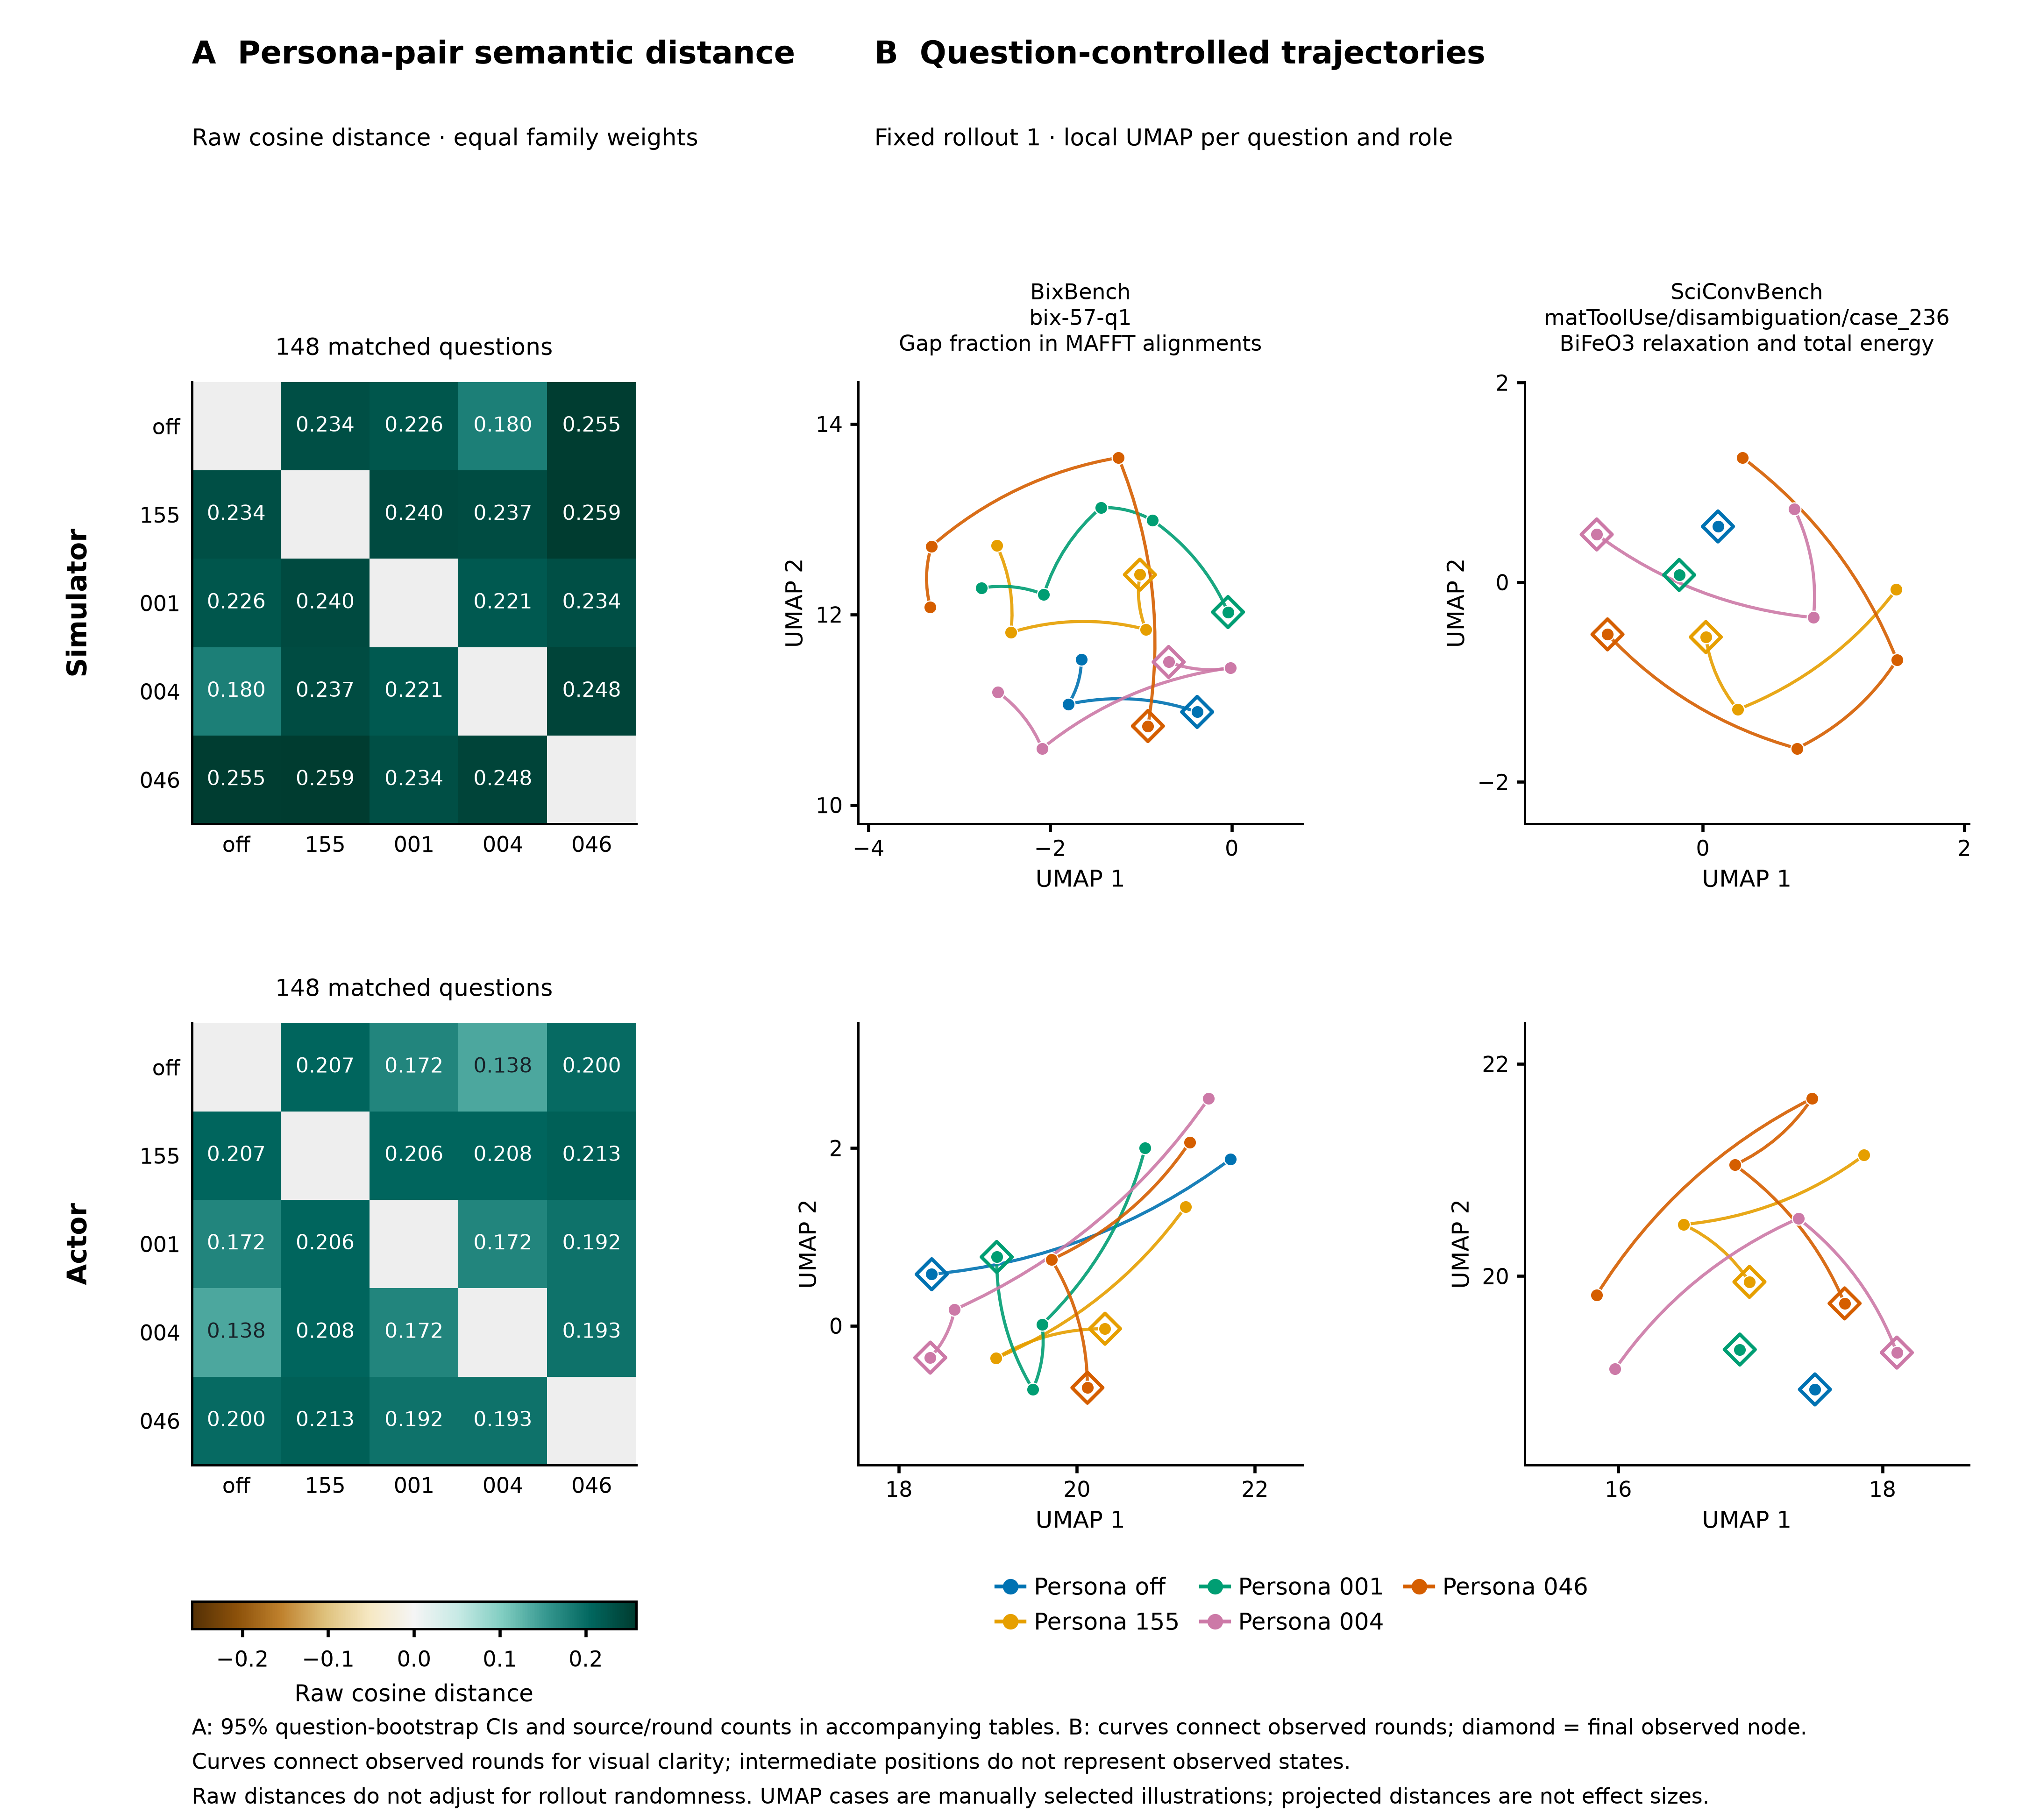

In [5]:
display(Markdown('```json\n'+(analyze.OUT/'cases.json').read_text()+'\n```'))
display(Code(Path(plot.__file__).read_text(),language='python'))
plot.main()
display(Image(filename=str(plot.FIG/'semantic.png'),width=1200))

In [6]:
import numpy as np
for role,v in summary.items():
    m=np.asarray(v['estimate']);assert np.allclose(m,m.T)
    assert np.all(np.diag(m)==0)
    assert np.isfinite(m).all()
assert len(rows)==10*len(c['roles'])
for v in summary.values():
    for family in v['family_counts']:
        assert np.isclose(sum(r['weight'] for r in v['question_weights'] if r['family']==family),.25)
coords=list(csv.DictReader((analyze.OUT/'trajectory_coordinates.csv').open()))
shown=[r for r in coords if r['displayed']=='True']
assert {int(r['trial']) for r in shown}=={c['display_rollout']}
assert {r['arm'] for r in shown}==set(c['arms'])
print('Validated: symmetric heatmaps, ten comparisons per role, fixed displayed rollout, all five settings, finite estimates.')

Validated: symmetric heatmaps, ten comparisons per role, fixed displayed rollout, all five settings, finite estimates.


## Interpretation
Panel A is aggregate evidence scoped to the matched selected questions. Panel B is illustrative. Raw distances do not account for within-persona rollout randomness. Language/style can affect distance; neither cosine distance nor a UMAP path measures task or reasoning quality. Full intervals, source counts, round coverage and exclusions are in `SEMANTIC_REPORT.md`.